# Training three models to compare

All three models use the same decoder-only Transformer (defined in `gated_attention_model.py`) and differ only inside attention in three waays:

| variant | what changes in each attention head | extra parameters per layer |
|---|---|---|
| `baseline` | softmax attention (standard): $\mathrm{softmax}(QK^T/\sqrt{d})V$ | 0 |
| `g1` | head output multiplied by a gate $g = \sigma(W_g x)$ (its a one learned scalar per head and token) computed from the hidden state $x$ entering attention | $d \cdot H + H$ |
| `sink` | one learned logit $b_h$ per head added once to every softmax as an extra option with a zero value vector: $a_{ij} = e^{s_{ij}} / (e^{b_h} + \sum_k e^{s_{ik}})$ | $H$ |

G1 is in between 0 and 1 (the range of scaling a head's output), while sink makes head output probability to nothing (abstain)

The comparison is maintained fair under
- Same tokenizer
- backbone size
- optimizer
- token budget
- batch order and evaluation schedule

In [4]:
import os
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

sys.path.insert(0, str(Path.cwd()))
from gated_attention_model import (TinyGPT, build_model, count_parameters, save_checkpoint,
                                   load_checkpoint, score_windows, pick_device, VARIANTS)




RUN_NAME = 'full' #os.environ.get('GA_RUN', 'smoke')
#REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
DATA_DIR =  '../../processed_data/gated_attention'   #REPO_ROOT / 'processed_data' / 'gated_attention' / RUN_NAME
CKPT_DIR =  '../../checkpoints/gated_attention'
RESULTS_DIR =  '../../results/gated_attention'

Path(CKPT_DIR).mkdir(parents=True, exist_ok=True)
Path(RESULTS_DIR).mkdir(parents=True, exist_ok=True)
device = pick_device()
meta = json.loads((Path(DATA_DIR) / 'meta.json').read_text())
print('run:', RUN_NAME, '| device:', device)

run: full | device: mps


## Experiment settings

- alter to have done a smoke test first

In [5]:
RUNS = {
    'smoke': dict(model=dict(d_model=64, n_layer=2, n_head=4, dropout=0.0),
                  seeds=[0], steps=60, batch_size=16, lr=2e-3, warmup=10, eval_every=20),
    'full':  dict(model=dict(d_model=256, n_layer=4, n_head=8, dropout=0.0),
                  seeds=[0, 1, 2], steps=3000, batch_size=32, lr=1e-3, warmup=150, eval_every=250),
}
cfg = RUNS['full']
model_config = dict(vocab_size=meta['vocab_size'], block_size=meta['block_size'], **cfg['model'])
WEIGHT_DECAY, BETAS, GRAD_CLIP, MIN_LR_FRAC = 0.1, (0.9, 0.95), 1.0, 0.1
RETRAIN = False        # True: retrain even if a finished checkpoint exists
(Path(RESULTS_DIR) / 'train_config.json').write_text(json.dumps(dict(model_config=model_config, **cfg, weight_decay=WEIGHT_DECAY,
                                                               betas=BETAS, grad_clip=GRAD_CLIP, min_lr_frac=MIN_LR_FRAC), indent=1))
model_config, cfg

({'vocab_size': 4096,
  'block_size': 256,
  'd_model': 256,
  'n_layer': 4,
  'n_head': 8,
  'dropout': 0.0},
 {'model': {'d_model': 256, 'n_layer': 4, 'n_head': 8, 'dropout': 0.0},
  'seeds': [0, 1, 2],
  'steps': 3000,
  'batch_size': 32,
  'lr': 0.001,
  'warmup': 150,
  'eval_every': 250})

## Load the saved data

Notebook 01 in notebooks folder handles all the data processing and story augmenting.

In [6]:
train_blocks = np.load(Path(DATA_DIR) / 'train_blocks.npy')
val_windows = pd.read_parquet(Path(DATA_DIR) / 'val_windows.parquet').to_dict('records')
eval_windows = pd.read_parquet(Path(DATA_DIR) / 'eval_windows.parquet').to_dict('records')

PAD_ID = meta['pad_id']

print(f'train blocks {train_blocks.shape}, val windows {len(val_windows)}, eval windows {len(eval_windows)}')
needed = cfg['steps'] * cfg['batch_size']
print(f'blocks needed: {needed:,} ({needed / len(train_blocks):.2f} passes over the training blocks)')

train blocks (110668, 257), val windows 1883, eval windows 4898
blocks needed: 96,000 (0.87 passes over the training blocks)


## Parameter counts

G1 adds one $d \times H$ matrix plus $H$ biases per layer

the sink adds $H$ numbers per layer.

In [7]:
init_models = {v: build_model(model_config, v, init_seed=0) for v in VARIANTS}
param_table = pd.DataFrame([dict(variant=v, total_params=count_parameters(m)[0], variant_only_params=count_parameters(m)[1])
                            for v, m in init_models.items()])
param_table['overhead_%'] = 100 * param_table.variant_only_params / param_table.total_params
param_table.to_csv(Path(RESULTS_DIR) / 'param_counts.csv', index=False)

# shared parameters are identical across variants at initialization
base_sd = init_models['baseline'].state_dict()
for v in ['g1', 'sink']:
    sd = init_models[v].state_dict()
    assert all(torch.equal(base_sd[k], sd[k]) for k in base_sd), v
print('shared parameters identical at init: OK')
param_table

shared parameters identical at init: OK


,variant,total_params,variant_only_params,overhead_%
0,baseline,4273664,0,0.000000
1,g1,4281888,8224,0.192065
2,sink,4273696,32,0.000749


## Baseline is G1 with every gate forced to 1

Copy the G1 model's shared weights into a baseline model and force all gates to 1. 
The logits should match to floating-point precision.

In [8]:
def gate_one_check(g1_model, n=4):
    g1_model = g1_model.to(device).eval()
    base = TinyGPT(**model_config, variant='baseline').to(device).eval()
    missing, unexpected = base.load_state_dict(g1_model.state_dict(), strict=False)
    assert not missing and all('.W_g.' in k for k in unexpected)
    x = torch.as_tensor(train_blocks[:n, :-1].astype(np.int64), device=device)
    ones = {l: torch.ones(model_config['n_head'], device=device) for l in range(model_config['n_layer'])}
    with torch.no_grad():
        diff = (g1_model(x, gate_override=ones) - base(x)).abs().max().item()
        learned_diff = (g1_model(x) - base(x)).abs().max().item()
    return diff, learned_diff

diff, learned_diff = gate_one_check(init_models['g1'])
print(f'max |logit diff| gates=1 vs baseline: {diff:.2e}   (learned gates vs baseline: {learned_diff:.2e})')
assert diff < 1e-4

max |logit diff| gates=1 vs baseline: 0.00e+00   (learned gates vs baseline: 8.28e-01)


## Training loop

Following the same training structure learned from lectures: using crossEntropyLoss, backward, optimizer step, and record the losss

Additions for comparisons:

- the block order comes from `np.random.default_rng(1000 + seed)` — the same for every variant;
- AdamW with linear warm-up then cosine decay
- every `eval_every` steps we compute validation loss

In [12]:
@torch.no_grad()
def evaluate(model, windows, batch_size=32):
    rows, _ = score_windows(model, windows, PAD_ID, device, batch_size=batch_size)
    return float(rows['loss'].mean())


def lr_at(step):
    if step < cfg['warmup']:
        return cfg['lr'] * (step + 1) / cfg['warmup']
    progress = (step - cfg['warmup']) / max(1, cfg['steps'] - cfg['warmup'])
    return cfg['lr'] * (MIN_LR_FRAC + (1 - MIN_LR_FRAC) * 0.5 * (1 + np.cos(np.pi * progress)))


def block_order(seed, n_needed):
    rng = np.random.default_rng(1000 + seed)          # data seed: independent of the variant
    order = []
    while len(order) < n_needed:
        order.extend(rng.permutation(len(train_blocks)).tolist())
    return np.array(order[:n_needed])


def train_model(variant, seed):
    model = build_model(model_config, variant, init_seed=seed).to(device)
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': WEIGHT_DECAY},
                                   {'params': no_decay, 'weight_decay': 0.0}], lr=cfg['lr'], betas=BETAS)
    criterion = nn.CrossEntropyLoss()
    order = block_order(seed, cfg['steps'] * cfg['batch_size'])
    out_dir = Path(CKPT_DIR) / f'{variant}_seed{seed}'
    out_dir.mkdir(parents=True, exist_ok=True)

    loss_val, curve = [], []
    best_val, best_step = float('inf'), -1
    t0 = time.time()
    with tqdm(total=cfg['steps'], desc=f'{variant} seed {seed}', unit='step', mininterval=20) as pbar:
        for step in range(cfg['steps']):
            model.train()
            idx = order[step * cfg['batch_size']:(step + 1) * cfg['batch_size']]
            batch = torch.as_tensor(train_blocks[idx].astype(np.int64), device=device)
            for group in optimizer.param_groups:
                group['lr'] = lr_at(step)
            optimizer.zero_grad()
            logits = model(batch[:, :-1])
            loss = criterion(logits.reshape(-1, logits.shape[-1]), batch[:, 1:].reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            loss_val.append(loss.item())
            pbar.update(1)
            if (step + 1) % cfg['eval_every'] == 0 or step + 1 == cfg['steps']:
                val_loss = evaluate(model, val_windows)
                curve.append(dict(step=step + 1, tokens=(step + 1) * batch[:, 1:].numel(),
                                  train_loss=float(np.mean(loss_val[-cfg['eval_every']:])), val_loss=val_loss,
                                  minutes=(time.time() - t0) / 60))
                if val_loss < best_val:
                    best_val, best_step = val_loss, step + 1
                    save_checkpoint(out_dir / 'best.pt', model, model_config, variant, seed=seed, step=step + 1,
                                    val_loss=val_loss, run=RUN_NAME)
                pbar.set_postfix({'train': f'{curve[-1]["train_loss"]:.3f}', 'val': f'{val_loss:.3f}'})
    save_checkpoint(out_dir / 'last.pt', model, model_config, variant, seed=seed, step=cfg['steps'],
                    val_loss=curve[-1]['val_loss'], run=RUN_NAME)
    pd.DataFrame(curve).to_csv(out_dir / 'val_curve.csv', index=False)
    np.save(out_dir / 'train_loss.npy', np.array(loss_val, dtype=np.float32))
    (out_dir / 'DONE').write_text(json.dumps(dict(best_step=best_step, best_val=best_val,
                                                  first_blocks=order[:8].tolist())))
    return best_step, best_val

In [ ]:
for seed in cfg['seeds']:
    for variant in VARIANTS:
        done = Path(CKPT_DIR) / f'{variant}_seed{seed}' / 'DONE'
        if done.exists() and not RETRAIN:
            print(f'{variant} seed {seed}: already trained ->', json.loads(done.read_text())['best_val'])
            continue
        best_step, best_val = train_model(variant, seed)
        print(f'{variant} seed {seed}: best val {best_val:.4f} at step {best_step}')

baseline seed 0: 100%|██████████| 3000/3000 [12:22<00:00,  4.04step/s, train=2.160, val=2.102]


baseline seed 0: best val 2.1015 at step 3000


g1 seed 0:   9%|▉         | 279/3000 [01:20<13:56,  3.25step/s, train=4.810, val=3.646]

### Same data order for every variant

The first training blocks seen by each model of a paired seed must be the same.

In [ ]:
first_blocks = {(v, s): tuple(json.loads((Path(CKPT_DIR) / f'{v}_seed{s}' / 'DONE').read_text())['first_blocks'])
                for s in cfg['seeds'] for v in VARIANTS}
for s in cfg['seeds']:
    assert len({first_blocks[(v, s)] for v in VARIANTS}) == 1
    print(f'seed {s}: first blocks', first_blocks[('baseline', s)])

seed 0: first blocks (17471, 25672, 101161, 94439, 93554, 100075, 19751, 87509)
seed 1: first blocks (109851, 35906, 110176, 20460, 292, 26704, 23773, 105434)
seed 2: first blocks (43360, 19526, 102047, 77683, 48754, 29494, 96003, 67901)


## Training curves

Left: training loss per step (smoothed). Right: validation loss at each scheduled evaluation; the selected checkpoint is the minimum.

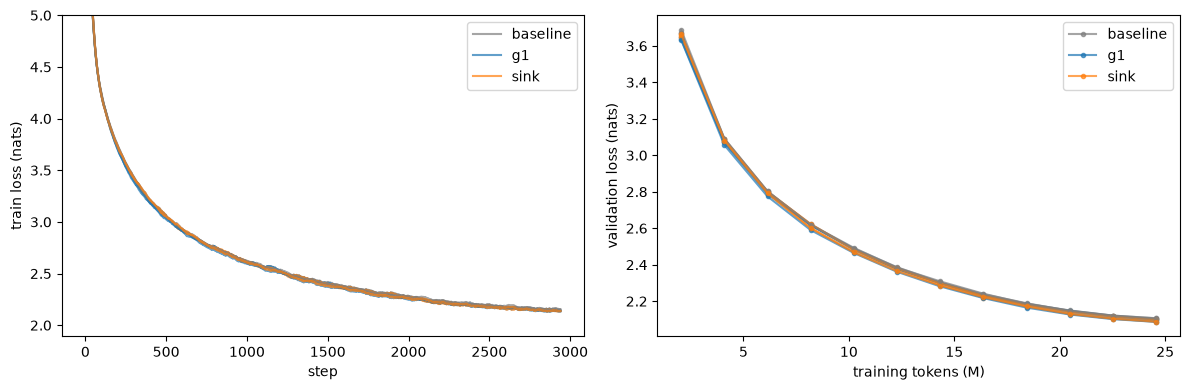

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {'baseline': 'tab:gray', 'g1': 'tab:blue', 'sink': 'tab:orange'}
curves = []
for s in cfg['seeds']:
    for v in VARIANTS:
        d = Path(CKPT_DIR) / f'{v}_seed{s}'
        tl = np.load(d / 'train_loss.npy')
        k = max(1, len(tl) // 50)
        axes[0].plot(np.convolve(tl, np.ones(k) / k, mode='valid'), color=colors[v], alpha=.7,
                     label=v if s == cfg['seeds'][0] else None)
        vc = pd.read_csv(d / 'val_curve.csv').assign(variant=v, seed=s)
        curves.append(vc)
        axes[1].plot(vc.tokens / 1e6, vc.val_loss, 'o-', color=colors[v], alpha=.7, ms=3,
                     label=v if s == cfg['seeds'][0] else None)
axes[0].set_xlabel('step'); axes[0].set_ylabel('train loss (nats)'); axes[0].legend()
axes[1].set_xlabel('training tokens (M)'); axes[1].set_ylabel('validation loss (nats)'); axes[1].legend()
axes[0].set_ylim(top=min(axes[0].get_ylim()[1], 5)); axes[1].set_ylim(top=min(axes[1].get_ylim()[1], 4))
plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / 'fig_training_curves.png', dpi=150)
plt.show()
curves = pd.concat(curves)
curves.to_csv(Path(RESULTS_DIR) / 'training_curves.csv', index=False)

## Checking on the trained G1 model: gates = 1 reproduces baseline attention

Same check as above, now with trained weights. Also reload one checkpoint from disk to confirm it gives the same validation loss as recorded during training.

In [ ]:
g1_trained, ck = load_checkpoint(Path(CKPT_DIR) / f'g1_seed{cfg["seeds"][0]}' / 'best.pt', device)
diff, learned_diff = gate_one_check(g1_trained)
print(f'trained G1: gates=1 vs baseline-with-same-weights max |logit diff| = {diff:.2e} '
      f'(with learned gates: {learned_diff:.2f})')
assert diff < 1e-3
reloaded_val = evaluate(g1_trained, val_windows)
print(f'reloaded checkpoint val loss {reloaded_val:.5f} vs recorded {ck["val_loss"]:.5f}')
assert abs(reloaded_val - ck['val_loss']) < 1e-3

trained G1: gates=1 vs baseline-with-same-weights max |logit diff| = 0.00e+00 (with learned gates: 16.36)


reloaded checkpoint val loss 2.09478 vs recorded 2.09478


## Held-out token losses (final eval split)

Each selected checkpoint scores every target in the eval split. We save one row per (variant, seed, story, target position) so later notebooks can make paired comparisons on identical tokens.

In [ ]:
loss_tables = []
for s in cfg['seeds']:
    for v in VARIANTS:
        model, ck = load_checkpoint(Path(CKPT_DIR) / f'{v}_seed{s}' / 'best.pt', device)
        rows, _ = score_windows(model, eval_windows, PAD_ID, device)
        loss_tables.append(pd.DataFrame(rows).assign(variant=v, seed=s, condition='learned' if v == 'g1' else 'standard'))
token_losses = pd.concat(loss_tables, ignore_index=True)
token_losses.to_parquet(Path(RESULTS_DIR) / 'eval_token_losses.parquet', index=False)
# every model scored exactly the same targets
keys = token_losses.groupby(['variant', 'seed']).apply(lambda d: hash(tuple(zip(d.story_id, d.target_pos))), include_groups=False)
assert keys.nunique() == 1
token_losses.head()

,story_id,target_pos,loss,variant,seed,condition
0,validation-0001599,256,2.151951,baseline,0,standard
1,validation-0001599,257,4.134629,baseline,0,standard
2,validation-0001599,258,3.610653,baseline,0,standard
3,validation-0001599,259,6.148520,baseline,0,standard
4,validation-0001599,260,3.078542,baseline,0,standard


## Main table: held-out performance by variant and paired seed

- `eval_loss`: mean next-token loss over all eval targets (nats); `eval_ppl` = exp(`eval_loss`).
- `Δ vs baseline`: paired difference with the baseline of the **same seed** (negative = better than baseline). The 95% interval resamples **whole eval stories** (2,000 bootstrap draws), so it describes uncertainty from the choice of held-out stories, not from training randomness. Training-seed variation is visible across the rows.

In [12]:
def story_bootstrap_diff(a, b, n_boot=2000, seed=0):
    """a, b: per-token losses aligned on the same (story, target) rows; returns mean diff and 95% CI
    from resampling stories."""
    d = pd.DataFrame({'story_id': a.story_id.values, 'diff': a.loss.values - b.loss.values})
    per_story = d.groupby('story_id')['diff'].agg(['sum', 'size'])
    sums, sizes = per_story['sum'].to_numpy(), per_story['size'].to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sums), size=(n_boot, len(sums)))
    boots = sums[idx].sum(1) / sizes[idx].sum(1)
    return sums.sum() / sizes.sum(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


sorted_losses = {k: g.sort_values(['story_id', 'target_pos']).reset_index(drop=True)
                 for k, g in token_losses.groupby(['variant', 'seed'])}
rows = []
for s in cfg['seeds']:
    for v in VARIANTS:
        d = sorted_losses[(v, s)]
        ck = torch.load(CKPT_DIR / f'{v}_seed{s}' / 'best.pt', map_location='cpu', weights_only=False)
        row = dict(variant=v, seed=s, params=int(param_table.set_index('variant').total_params[v]),
                   best_step=ck['step'], val_loss=ck['val_loss'], eval_loss=d.loss.mean(), eval_ppl=np.exp(d.loss.mean()))
        if v != 'baseline':
            m, lo, hi = story_bootstrap_diff(d, sorted_losses[('baseline', s)])
            row.update(delta_vs_baseline=m, delta_ci_low=lo, delta_ci_high=hi)
        rows.append(row)
main_table = pd.DataFrame(rows)
main_table.to_csv(RESULTS_DIR / 'main_table.csv', index=False)
main_table.round(4)

,variant,seed,params,best_step,val_loss,eval_loss,eval_ppl,delta_vs_baseline,delta_ci_low,delta_ci_high
0,baseline,0,4273664,3000,2.1015,2.0865,8.0563,NaN,NaN,NaN
1,g1,0,4281888,3000,2.0948,2.0765,7.9768,-0.0099,-0.0114,-0.0084
2,sink,0,4273696,3000,2.0866,2.0707,7.9301,-0.0158,-0.0170,-0.0145
3,baseline,1,4273664,3000,2.1067,2.0911,8.0937,NaN,NaN,NaN
4,g1,1,4281888,3000,2.1011,2.0872,8.0626,-0.0038,-0.0054,-0.0023
5,sink,1,4273696,3000,2.0999,2.0843,8.0392,-0.0068,-0.0081,-0.0055
6,baseline,2,4273664,3000,2.1059,2.0911,8.0935,NaN,NaN,NaN
7,g1,2,4281888,3000,2.0866,2.0699,7.9237,-0.0212,-0.0227,-0.0197
8,sink,2,4273696,3000,2.0884,2.0729,7.9475,-0.0182,-0.0195,-0.0170


In [13]:
summary = (main_table.groupby('variant', sort=False)
           .agg(seeds=('seed', 'size'), eval_loss_mean=('eval_loss', 'mean'), eval_loss_sd=('eval_loss', 'std'),
                eval_ppl_mean=('eval_ppl', 'mean'), delta_mean=('delta_vs_baseline', 'mean'),
                delta_min=('delta_vs_baseline', 'min'), delta_max=('delta_vs_baseline', 'max')))
summary.to_csv(RESULTS_DIR / 'main_table_summary.csv')
summary.round(4)

,seeds,eval_loss_mean,eval_loss_sd,eval_ppl_mean,delta_mean,delta_min,delta_max
variant,,,,,,,
baseline,3,2.0895,0.0027,8.0812,NaN,NaN,NaN
g1,3,2.0779,0.0088,7.9877,-0.0117,-0.0212,-0.0038
sink,3,2.0760,0.0073,7.9723,-0.0136,-0.0182,-0.0068


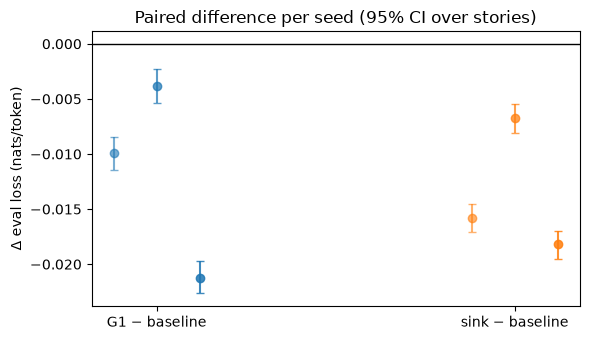

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, v in enumerate(['g1', 'sink']):
    d = main_table[main_table.variant == v]
    for j, r in enumerate(d.itertuples()):
        ax.errorbar(i + (j - 1) * 0.12, r.delta_vs_baseline,
                    yerr=[[r.delta_vs_baseline - r.delta_ci_low], [r.delta_ci_high - r.delta_vs_baseline]],
                    fmt='o', color=colors[v], capsize=3, label=f'seed {r.seed}' if i == 0 else None, alpha=.6 + .13 * j)
ax.axhline(0, color='k', lw=1)
ax.set_xticks([0, 1], ['G1 − baseline', 'sink − baseline'])
ax.set_ylabel('Δ eval loss (nats/token)')
ax.set_title('Paired difference per seed (95% CI over stories)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_main_deltas.png', dpi=150)
plt.show()